In [1]:
import wandb
import numpy as np
import pandas as pd

from matplotlib import pyplot as plt

In [2]:
api = wandb.Api(api_key='4a3e44e53460799e4aae1531c4bdfbd4e22f82ce')

In [3]:
path = 'kprotopapas/rl_experiments'

In [4]:
alg = 'deqa'

In [5]:
runs = api.runs(path=path, filters={'group': f'{alg}_v1_inexact'})

In [6]:
dfs = {d: [] for d in [1, 5, 10, 15, 20]}
dfs

{1: [], 5: [], 10: [], 15: [], 20: []}

In [7]:
for run in runs:
    temp = run.history(keys=['samples'], x_axis='_step')\
        .rename(columns={'_step': 'k', 'samples': f'smp_{run.id}'})
    
    if len(temp) > 80:    
        temp = temp.set_index('k')
        depth = int(run.config['algorithm'][:-5])
        dfs[depth].append(temp)
    

In [8]:
{k: len(v) for k, v in dfs.items()}

{1: 64, 5: 64, 10: 64, 15: 64, 20: 64}

In [9]:
joined = {k: pd.concat(v, axis=1) for k, v in dfs.items()}

In [10]:
stds = {k: v.std(axis=1).rename(f'{k}-std') for k, v in joined.items()}
means = {k: v.mean(axis=1).rename(f'{k}-mean') for k, v in joined.items()}

In [11]:
means_df = pd.concat(means.values(), axis=1).iloc[:80]
stds_df = pd.concat(stds.values(), axis=1).iloc[:80]

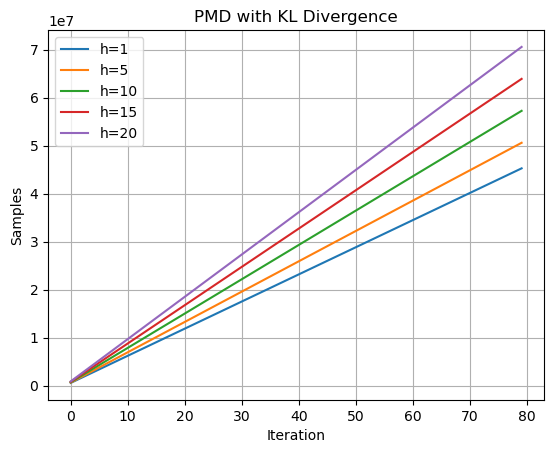

In [12]:
fig, ax = plt.subplots()
ax.plot(means_df)
for name, col in stds_df.items():
    depth = int(name[:-4])
    mean_name = f'{depth}-mean'
    mean = means_df[mean_name]
    ax.fill_between(col.index, mean - col, mean + col, alpha=0.2)
    ax.grid(visible=True)

ax.set_xlabel('Iteration')
ax.set_ylabel('Samples')
legends = [f'h={depth}' for depth in [1, 5, 10, 15, 20]]
ax.legend(legends)
ax.set_title('PMD with KL Divergence')
plt.savefig(f'{alg}.png')